# PRE-PROCESSING OF Knee osteoarthritis DATASET

During the eda, we notice two problems:
- Img do not have the same sizes
- The test folder is umbalanced and do not have enough img

In [ ]:
import os
import numpy as np
from PIL import Image
from sklearn.preprocessing import LabelEncoder

### Transform each img and their label into numpy arrays for model training

In [ ]:
pro_train_dir = "../Dataset_Knee_Osteoarthritis_Balanced/train"
pro_val_dir = "../Dataset_Knee_Osteoarthritis_Balanced/val"
pro_test_dir = "../Dataset_Knee_Osteoarthritis_Balanced/test"

def transform_img(folder):
    images = []
    labels = []
    for label in os.listdir(folder):
        label_path = os.path.join(folder, label)
        for file in os.listdir(label_path):
            file_path = os.path.join(label_path, file)
            img = Image.open(file_path)
            img_array = np.array(img)
            images.append(img_array)
            labels.append(label)
    return np.array(images), np.array(labels)

### Affect features (img) and labels (HEALTHY or SICK)

In [4]:
X_train, y_train = transform_img(pro_train_dir)
X_val, y_val = transform_img(pro_val_dir)
X_test, y_test = transform_img(pro_test_dir)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(5777, 224, 224)
(826, 224, 224)
(1656, 224, 224)


### Shuffle values

In [5]:
from sklearn.utils import shuffle

X_train, y_train = shuffle(X_train, y_train, random_state=42)
X_val, y_val = shuffle(X_val, y_val, random_state=42)
X_test, y_test = shuffle(X_test, y_test, random_state=42)

### Reshape features to only have one pixels

In [6]:
h, w = X_train.shape[1], X_train.shape[2]

X_train = X_train.reshape(len(X_train), h * w)
X_val = X_val.reshape(len(X_val), h * w)
X_test = X_test.reshape(len(X_test), h * w)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(5777, 50176)
(826, 50176)
(1656, 50176)


### Encode the labels to  affect digits to each labels

In [7]:
encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_val = encoder.transform(y_val)
y_test = encoder.transform(y_test)

print("y_train:", y_train)
print("y_val:", y_val)
print("y_test:", y_test)

y_train: [0 1 0 ... 0 0 1]
y_val: [0 1 1 1 1 1 0 1 0 0 0 1 0 1 1 0 1 1 0 1 0 1 0 1 0 0 1 1 0 1 1 1 1 1 1 0 1
 1 0 1 1 1 1 0 1 1 0 1 1 0 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 0 1 1 0 1 1
 1 0 1 1 0 1 1 0 1 1 0 1 1 0 0 0 1 1 1 0 1 0 0 0 1 1 0 1 1 1 0 0 1 1 1 1 1
 1 1 0 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 1 0 0 0 1 0 1 1 1 0
 0 1 1 1 0 1 0 0 1 0 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 0 1
 1 0 0 0 1 0 1 1 1 0 0 0 1 1 0 0 1 1 0 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 0 0 0 1 1 0 1 1 1 0 1 1 0 1 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 1 0
 1 1 1 0 1 1 1 0 0 1 1 1 0 1 1 0 0 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 0
 1 0 0 1 1 0 0 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 0 1 1 1 0 0 0 0 1 0 0 1 0 0
 1 0 1 0 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 0 1 1 0 1
 1 1 0 0 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 0 1 0 0
 0 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0 1 1 0 0 1 1 0 0 0 1 1 1 0 0 1 1 0 0 1 0 1
 0 0 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 0 1 0

# Model Training: Machine Learning Approach

Now that our image data is pre-processed and flattened into 1D vectors, we can proceed to the training phase. We will train and compare three classic Machine Learning algorithms to see which one performs best on our data:
1. Support Vector Machine (SVM)
2. Random Forest Classifier
3. Logistic Regression (The classification equivalent of linear regression)

### Data Normalization
Before training, we need to scale the pixel values to a range between 0 and 1. This helps the algorithms process the data faster and more accurately.

In [8]:
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Data normalized! Max value:", X_train.max())
# En faisant $X / 255.0$ 
# Cela permet au modèle de faire ses calculs mathématiques beaucoup plus 
# vite et avec plus de précision.

Data normalized! Max value: 1.0


### Support Vector Machine (SVM)
First, we will train the SVM model. It is a reliable algorithm for binary classification tasks.

In [9]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Initialize and train the SVM model
svm_model = SVC(random_state=42)
print("Training SVM...")
svm_model.fit(X_train, y_train)
print("SVM training completed.")

# Predict on the test set
y_pred_svm = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, y_pred_svm)
print(f"Accuracy Random Forest : {svm_accuracy * 100:.2f}%")


Training SVM...
SVM training completed.
Accuracy Random Forest : 64.79%


Let's evaluate the SVM performance using a confusion matrix to see exactly where the model makes mistakes.

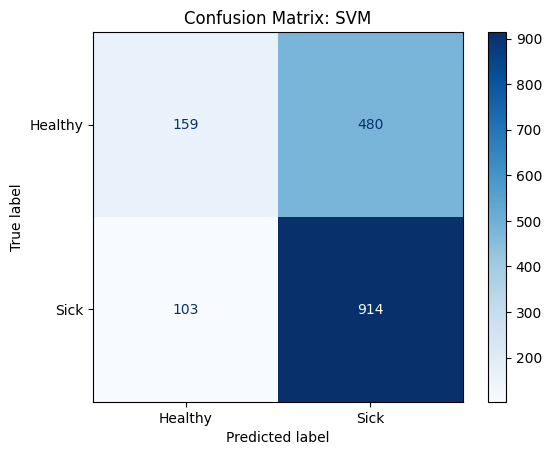

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report

# Generate and plot confusion matrix for SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=["Healthy", "Sick"])

disp_svm.plot(cmap='Blues')
plt.title("Confusion Matrix: SVM")
plt.show()

# print("Accuracy SVM:", accuracy_score(y_test, y_pred_svm))
# print(classification_report(y_test, y_pred_svm, target_names=["Healthy", "Sick"]))

**SVM Conclusion:**
The matrix shows that the SVM model achieves a baseline accuracy of around 64%. However, it struggles to correctly identify the "Sick" patients, producing many false negatives. In a medical context, missing a sick patient is a critical error.

### Random Forest Classifier
Next, we will train a Random Forest model. This algorithm builds multiple decision trees and merges them together to get a more accurate and stable prediction.

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(random_state=42)
print("Training Random Forest...")
rf_model.fit(X_train, y_train)
print("Random Forest training completed.")

# Predict on the test set
y_pred_rf = rf_model.predict(X_test)

# Accuracy score
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy Random Forest : {rf_accuracy * 100:.2f}%")


Training Random Forest...
Random Forest training completed.
Accuracy Random Forest : 65.52%


Let's look at the confusion matrix for the Random Forest model to see if it performs better than the SVM.

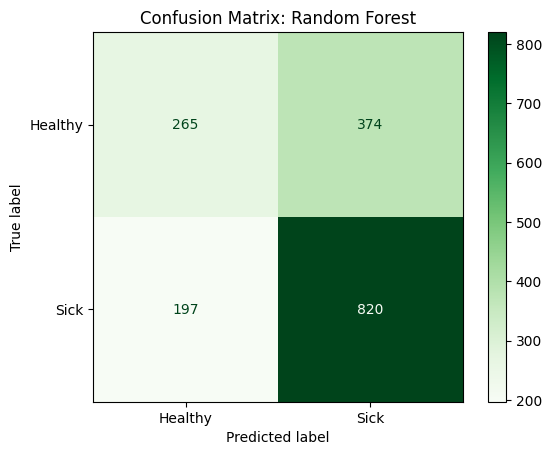

Accuracy Random Forest: 0.6551932367149759
              precision    recall  f1-score   support

     Healthy       0.57      0.41      0.48       639
        Sick       0.69      0.81      0.74      1017

    accuracy                           0.66      1656
   macro avg       0.63      0.61      0.61      1656
weighted avg       0.64      0.66      0.64      1656



In [ ]:
# Generate and plot confusion matrix for Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Healthy", "Sick"])

disp_rf.plot(cmap='Greens')
plt.title("Confusion Matrix: Random Forest")
plt.show()

# print("Accuracy Random Forest:", accuracy_score(y_test, y_pred_rf))
# print(classification_report(y_test, y_pred_rf, target_names=["Healthy", "Sick"]))

**Random Forest Conclusion:**
The matrix indicates the performance of the Random Forest. We observe how the true positives and false negatives have shifted compared to the SVM.

### Logistic Regression
Finally, we train a Logistic Regression model. It is a fundamental linear algorithm used for binary classification that estimates the probability of an image belonging to the "Sick" or "Healthy" class.

In [13]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42, max_iter=1000)
print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)
print("Logistic Regression training completed.")

y_pred_lr = lr_model.predict(X_test)

# Accuracy score
lr_accuracy = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy Random Forest : {lr_accuracy * 100:.2f}%")


Training Logistic Regression...


/home/harry-hounsou/Ridwane777/semester4/medical-vision-ml/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression training completed.
Accuracy Random Forest : 64.19%


Let us generate the confusion matrix for the Logistic Regression model to complete our baseline comparisons.

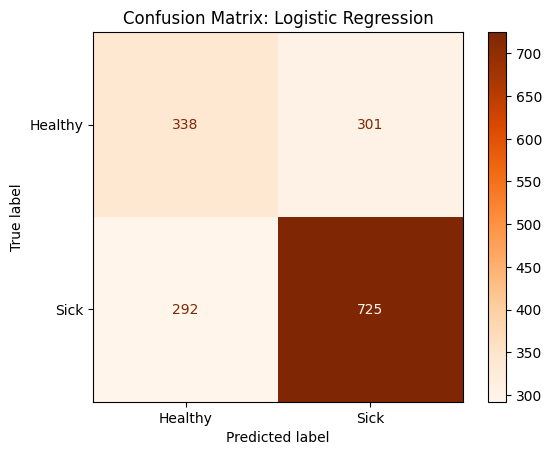

Accuracy Logistic Regression: 0.6419082125603864


In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["Healthy", "Sick"])
disp_lr.plot(cmap='Oranges')
plt.title("Confusion Matrix: Logistic Regression")
plt.show()

# print("Accuracy Logistic Regression:", accuracy_score(y_test, y_pred_lr))

**Logistic Regression Conclusion & Base Models Comparison:**

We have now tested three different algorithms with their default parameters. By comparing the matrices, we can identify which model naturally handles our flattened image data best. However, default parameters are rarely optimal.